# Sequence Analysis Quiz

Quiz on two NCBI sequences (`NC_035298.fasta` and `MK312630.fasta`): sequence manipulation, composition plots, protein synthesis and alignment. The task is in `exercises/Sequence Analysis Quiz.md`.

In [1]:
import Bio
from Bio.Seq import Seq
from Bio import SeqIO

In [2]:
from io import StringIO

from Bio import Entrez, SeqIO

Entrez.email = "your.email@example.com"  # NCBI asks for a contact address


def fetch_record(accession, rettype="fasta"):
    """Download a nucleotide record from NCBI and parse it."""
    with Entrez.efetch(db="nuccore", id=accession, rettype=rettype, retmode="text") as handle:
        return SeqIO.read(StringIO(handle.read()), "fasta" if rettype == "fasta" else "gb")


seqA = fetch_record('NC_035298').seq
seqB = fetch_record('MK312630').seq

1. Sequence Manipulation

In [3]:
print('a. Total Length')
print('   Total length of Seq A: ', len(seqA))
print('   Total length of Seq B: ', len(seqB))

print('-------------------------------------')
print('b. Index of GCT in sequence A: ', seqA.find('GCT'))
print('   Index of GCT in sequence B: ', seqB.find('GCT'))

print('-------------------------------------')
first13 = seqA[:13]
last2 = seqB[-2:]
seqC = (first13 + last2)[::-1]
print(f"c. Sequence C: {seqC}")

a. Total Length
   Total length of Seq A:  174848
   Total length of Seq B:  12381
-------------------------------------
b. Index of GCT in sequence A:  18
   Index of GCT in sequence B:  50
-------------------------------------
c. Sequence C: AAAGTTTGAGAGGTA


2. Sequence Analysis & Plotting

a. Determine and display nucleotides base


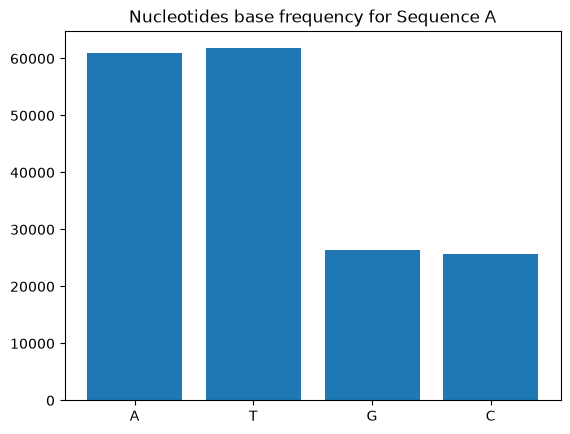

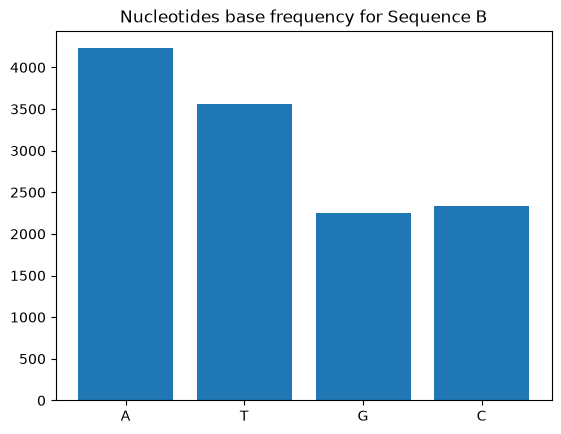

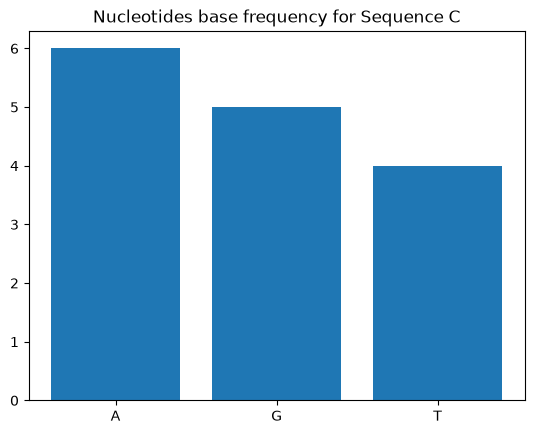

In [4]:
import matplotlib.pyplot as plt
from collections import Counter

print('a. Determine and display nucleotides base')
seqA_freq = Counter(seqA)
seqB_freq = Counter(seqB)
seqC_freq = Counter(seqC)
plt.title('Nucleotides base frequency for Sequence A')
plt.bar(seqA_freq.keys(), seqA_freq.values())
plt.show()
plt.title('Nucleotides base frequency for Sequence B')
plt.bar(seqB_freq.keys(), seqB_freq.values())
plt.show()
plt.title('Nucleotides base frequency for Sequence C')
plt.bar(seqC_freq.keys(), seqC_freq.values())
plt.show()


In [5]:
from Bio.SeqUtils import gc_fraction

print('b. Display GC & AT content percentage for Sequence A, B, and C')

seqA_GC = gc_fraction(seqA)*100
seqA_AT = 100 - seqA_GC
seqB_GC = gc_fraction(seqB)*100
seqB_AT = 100 - seqB_GC
seqC_GC = gc_fraction(seqC)*100
seqC_AT = 100 - seqC_GC

print(f"SeqA GC Percentage: {seqA_GC:.2f}%, AT Percentage: {seqA_AT:.2f}%")
print(f"Seqb GC Percentage: {seqB_GC:.2f}%, AT Percentage: {seqB_AT:.2f}%")
print(f"SeqC GC Percentage: {seqC_GC:.2f}%, AT Percentage: {seqC_AT:.2f}%")

b. Display GC & AT content percentage for Sequence A, B, and C
SeqA GC Percentage: 29.78%, AT Percentage: 70.22%
Seqb GC Percentage: 37.05%, AT Percentage: 62.95%
SeqC GC Percentage: 33.33%, AT Percentage: 66.67%


In [6]:
from Bio.SeqUtils import MeltingTemp as mt
print("c. Melting Temperature")

print('Melting temperature for seq A: ', mt.Tm_Wallace(seqA))
print('Melting temperature for seq B: ', mt.Tm_Wallace(seqB))
print('Melting temperature for seq C: ', mt.Tm_Wallace(seqC))

c. Melting Temperature
Melting temperature for seq A:  453820.0
Melting temperature for seq B:  33936.0
Melting temperature for seq C:  40.0


In [7]:
from Bio.SeqUtils import molecular_weight as mw
print("d. Molecular Weight")

print('Molecular Weight for seq A: ', mw(seqA))
print('Molecular Weight for seq B: ', mw(seqB))
print('Molecular Weight for seq C: ', mw(seqC))

d. Molecular Weight
Molecular Weight for seq A:  54010577.6417
Molecular Weight for seq B:  3825779.3347
Molecular Weight for seq C:  4760.0566


3. DNA & mRNA Protein Synthesis

In [8]:
print("a. Transcribe and display the DNA Sequence A, B, and C into mRNA sequence")
transcript_a = seqA.transcribe()
transcript_b = seqB.transcribe()
transcript_c = seqC.transcribe()
print("   - Sequence A has an antitemplate of: ", transcript_a )
print("   - Sequence B has an antitemplate of: ", transcript_b )
print("   - Sequence C has an antitemplate of: ", transcript_c )

a. Transcribe and display the DNA Sequence A, B, and C into mRNA sequence
   - Sequence A has an antitemplate of:  ...
   - Sequence B has an antitemplate of:  AUGAGUAUUACCACUAUGAAAGGAGUUACAUCAGAGAGUCCUGCCGAAGCGCUUUCCCGCUUCCAAACUACUGGAUUGACGUUGAACAACCCCAAGGACCUUUACUGGAUGACAGAAUUUUUGAAGGAAGAAUUUUACGACAAGGGAAACUAUUAUUAUCCCAUCAAAACGGUAUGUGAUGGCGAACUCAUCGAAACCGAGCUCUUCUGUCCCUUCGAACCAAAGCUCAGUCCACAUUACAUUCAAUUAUACAACUCUCGUGAUGAGCGAUCCAACUUGUACGCCGUUCCGCCCAAGAAAACAGACAUGAAAAAGUACAAUCGUAUAAAUUGUGAGAAAAUGGGUUCUUUGAUGGCCCCUAAUUCCAAUUAUGACGACACAGAAAUGGUUUCUCUCUUCUACUCCAUGAUGUACUACCUCAAUGAUCAGACCGCUCAUCUUAAGCUCCCUGAAGAAGAUAUUCAACCUGAGCUUGUUGAUGAACUCAACGACCAUGUCUUACAGUAUCUAAGUGUGUUCCUUAGCAUCUUUAAACCGCGUGAACCUCAAGAUUUGGAGCGAAUCUGGAAUUUUUUGGACUUUUACCAGCCAUAUUUCAAGAAAGUUGAUGGCAAGAUUAUCUUGCACGAGAAAUAUCAGGGGCGUACUCCACCACAAAUCGGUUUGAUCAAGAAAAUAACAGGUUAUGUAUUAGAGAGGUUUGCUCCGAAAAAGAAUAUCACUCAAGUCAUCUACGAGGUCAUCAGAUAUAUCAAGGGAAUCAAGCAAGAAAUUAAGAUUCGAGGUGAUAAGAGCUUCACUCUGUCUCUCAAAGAGUAUGAUGAGUUCCGUGACCAAGUU

In [9]:
print("b. Translate and display mRNA Sequence A, B, and C into amino acids sequence")
print("   - Sequence A has an antitemplate of: ", transcript_a.translate())
print("   - Sequence B has an antitemplate of: ", transcript_b.translate())
print("   - Sequence C has an antitemplate of: ", transcript_c.translate())

b. Translate and display mRNA Sequence A, B, and C into amino acids sequence
   - Sequence A has an antitemplate of:  MESLILAQDERWRYALHMQVERKL*L*WRTGE*HVRIYL*EGNNNWKRLLTSHML*SEIIFCLEMSLRLIS*LVR*WLTKATISSWFERTISHTGTETRSRLLRKAAVGNFPQWAKA*RSNTA*GMNACGL*TSFIGEEF*RYPKNKHRLTPCQQPR*YGGCKRYPELLGVKSLQVVS*VCC*ILELNSKQAVETIILEYGRGKGNSQCSGEMRRYWEEHQKRKRFAGPLLTLRDES*GSEWD*IPQ*S*P*TMDTRCCAYRSVQYRS*RVKYPAWEVCSQE*NSKELTGARTSGGACGLIRCNTKNLTRI*HVVDFYESRKCLREHEHRWCMAVVSSCREMLG*VPQRAQPLFLVAII*LGTLKRLPVTNRRKVRMTSSQHAPYILGYTRATMGMTKSC*TVKSSQSLNIFSVRIVG*NSPT*RWNR**SPVSYTAVNPFPGLVHTARHTTGAGHARSYCLALSVPKVGLVTGVKS*QGSRTGRCGWITSLLGIYLFISDRYI*RAISSVG*SAPLIRVRSQVQILDSPDLGGYSSVGRALLLQGRCQRFESAYLQRYI*LF*IYIYCAYVYVCVN*LLLVSSKLRLTMDTLAFRSDEGRDYQRNISVSWK*AMTRKFPNEETLYTVY*IHK*IRANLVN*NILVTKGKESKSDFLSSGERKGNSLNHFNAF*WGRGTLVT*LSKIS*NSWNIVP**GESPVGENV*KIINVSQVAWDT*NPV*ISEDHLVRLNIPK*PIVN*YREGKVKRTPGGE*NRT*NRKLTSSRRTTYRLTMCMLKNEPATYK*WQVKIENIGAIVKASLNRALVTVYRPEPE*SNHGQGEA*VVLSGGPNRLMLKNQRTSCG*G*NANRIRS*LVLPEMRFGAAVDAIA*G*STV

C:\Users\jorda\Code\ml-notebooks\courses\computational-biology\.venv\Lib\site-packages\Bio\Seq.py:2874: BiopythonWarning: Partial codon, len(sequence) not a multiple of three. Explicitly trim the sequence or add trailing N before translation. This may become an error in future.
  warnings.warn(


4. Sequence Alignment & Similarities

In [10]:
from Bio.Align import PairwiseAligner

# local alignment, xx scoring: match = 1, mismatch = 0, no gap penalty
aligner = PairwiseAligner(mode='local', match_score=1, mismatch_score=0, open_gap_score=0, extend_gap_score=0)

print('a. SeqA and Seq("TAACGCGTTAAGTATCCCG")')

alignments_SeqA = aligner.align(seqA, 'TAACGCGTTAAGTATCCCG')

top_alignment = alignments_SeqA[0]
print(top_alignment)

print(f'Sequence A alignment score: {top_alignment.score}')

a. SeqA and Seq("TAACGCGTTAAGTATCCCG")
target            1 TGGAGAGTTTGATCCTGGCTCAGGATGAACGCTGGCGGTATGCCTTACACATGCAAGTCG
                  0 |--|-|-------|--|-|---|--|------|------|------|-----|----|--
query             0 T--A-A-------C--G-C---G--T------T------A------A-----G----T--

target           61 AACGAAAGCTTTAGCTTTAGTGGCGAACG 90
                 60 |--------|----|--------|---|| 89
query            13 A--------T----C--------C---CG 19

Sequence A alignment score: 19.0


In [11]:
print('b. SeqB and Seq("CAGTGCGCTAGCAGCTACGTGTG")')

alignments_SeqB = aligner.align(seqB, 'CAGTGCGCTAGCAGCTACGTGTG')

top_alignment = alignments_SeqB[0]
print(top_alignment)

print(f'Sequence B alignment score: {top_alignment.score}')

b. SeqB and Seq("CAGTGCGCTAGCAGCTACGTGTG")
target           10 CCACTATGAAAGGAGTTACATCAGAGAGTCCTGCCGAAGCGCTTTCCCGCTTCCAAACTA
                  0 |-|----|-------|-------|-----|--||--------|-----------|-----
query             0 C-A----G-------T-------G-----C--GC--------T-----------A-----

target           70 CTGGATTGACGTTGAACAACCCCAAGGACCTTTACTGGATGACAGAATTTTTG 123
                 60 --|------|----|----------|--|-|--||-|--||------|----| 113
query            10 --G------C----A----------G--C-T--AC-G--TG------T----G  23

Sequence B alignment score: 23.0


In [12]:
from Levenshtein import distance
print('Levenshtein distance of Seq A and Seq B: ', distance(seqA, seqB))

Levenshtein distance of Seq A and Seq B:  162467
